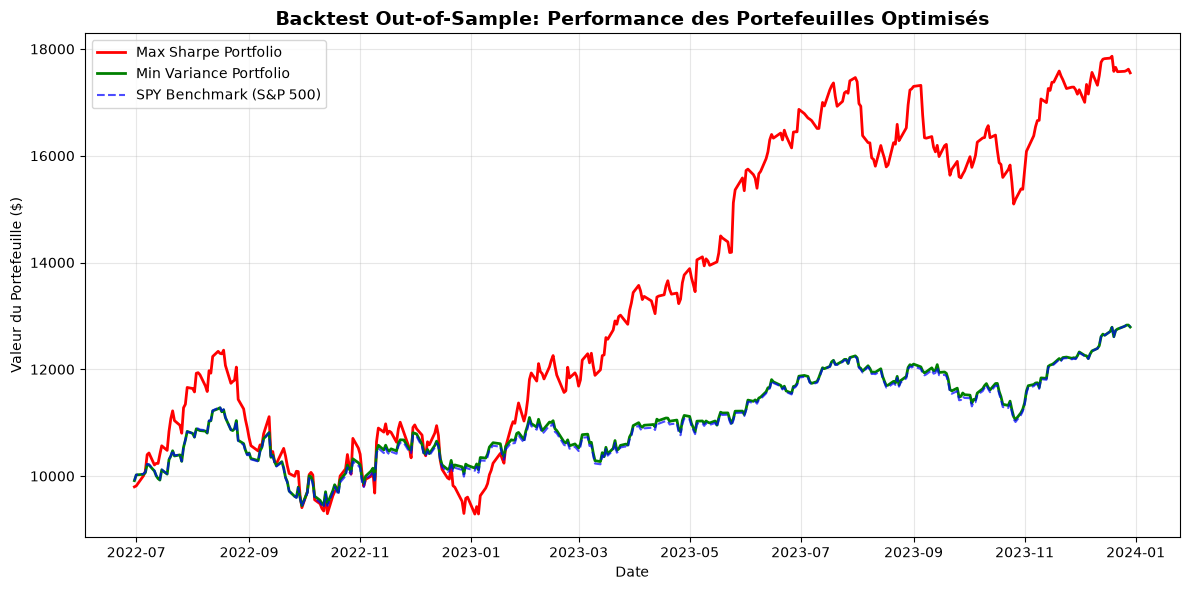

--- Performances Out-of-Sample ---
                      Max Sharpe Min Variance SPY Benchmark
Total Return              79.14%       29.02%        29.02%
CAGR                      47.50%       18.52%        18.52%
Annualized Volatility     28.59%       17.04%        17.16%
Sharpe Ratio             159.12%       96.94%        96.24%
Max Drawdown             -24.84%      -16.27%       -16.68%


In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from marketlens.backtest import calculate_backtest_stats, run_backtest
from marketlens.portfolio import (
    optimize_minimum_variance,
    optimize_sharpe_ratio,
)
from marketlens.returns import calculate_simple_returns

# 1. Charger les données de prix nettoyées
prices = pd.read_csv(
    "../data/processed/cleaned_prices.csv", index_col=0, parse_dates=True
)
daily_returns = calculate_simple_returns(prices)

# 2. Séparation In-Sample (70%) / Out-of-Sample (30%)
split_idx = int(len(daily_returns) * 0.70)
in_sample_returns = daily_returns.iloc[:split_idx]
out_sample_returns = daily_returns.iloc[split_idx:]

# 3. Optimisation des poids sur la période In-Sample uniquement
in_sample_mean = in_sample_returns.mean()
in_sample_cov = in_sample_returns.cov()

max_sharpe_weights, _ = optimize_sharpe_ratio(in_sample_mean, in_sample_cov)
min_vol_weights, _ = optimize_minimum_variance(in_sample_mean, in_sample_cov)

# 4. Simulation du Backtest Out-of-Sample (Capital Initial = $10,000)
capital = 10000.0
eq_max_sharpe = run_backtest(out_sample_returns, max_sharpe_weights, capital)
eq_min_vol = run_backtest(out_sample_returns, min_vol_weights, capital)

# Benchmark: Portefeuille 100% SPY
spy_weights = [1.0 if col == "SPY" else 0.0 for col in prices.columns]
eq_spy = run_backtest(out_sample_returns, spy_weights, capital)

# 5. Visualisation des Courbes de Capital (Equity Curves)
plt.figure(figsize=(12, 6))
plt.plot(eq_max_sharpe, label="Max Sharpe Portfolio", color="red", linewidth=2)
plt.plot(eq_min_vol, label="Min Variance Portfolio", color="green", linewidth=2)
plt.plot(
    eq_spy,
    label="SPY Benchmark (S&P 500)",
    color="blue",
    linestyle="--",
    alpha=0.7,
)

plt.title(
    "Backtest Out-of-Sample: Performance des Portefeuilles Optimisés",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date")
plt.ylabel("Valeur du Portefeuille ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Sauvegarde de la figure
plt.savefig("../reports/figures/06_backtest_equity_curves.png")
plt.show()

# 6. Tableau récapitulatif des performances Out-of-Sample
stats_df = pd.DataFrame(
    {
        "Max Sharpe": calculate_backtest_stats(eq_max_sharpe),
        "Min Variance": calculate_backtest_stats(eq_min_vol),
        "SPY Benchmark": calculate_backtest_stats(eq_spy),
    }
)

print("--- Performances Out-of-Sample ---")
print(
    stats_df.map(
        lambda x: f"{x:.2%}" if isinstance(x, float) and abs(x) < 5 else f"{x:.2f}"
    )
)

In [4]:
# Sauvegarder le résumé du backtest
stats_df.to_csv("../reports/figures/06_backtest_metrics.csv")
print(
    "Métriques sauvegardées avec succès dans reports/figures/06_backtest_metrics.csv"
)

Métriques sauvegardées avec succès dans reports/figures/06_backtest_metrics.csv
